<a href="https://colab.research.google.com/github/nopharshalom/DeepLearning-Assignment-2-RNNs-Transformers/blob/main/Deep_Learning_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Deep Learning - Assignment 2
##Nophar Shalom, Usman Ali
Loading Penn Tree Bank (word-level)

In [42]:
import torch, urllib.request

device = "cuda" if torch.cuda.is_available() else "cpu"

url = "https://raw.githubusercontent.com/tomsercu/lstm/master/data/ptb.{}.txt"

def load(split):
    text = urllib.request.urlopen(url.format(split)).read().decode()
    return text.replace("\n", " <eos> ").split()

train_words = load("train")
valid_words = load("valid")
test_words  = load("test")

vocab = sorted(set(train_words))
word2idx = {w: i for i, w in enumerate(vocab)}

train_ids = torch.tensor([word2idx[w] for w in train_words])
valid_ids = torch.tensor([word2idx[w] for w in valid_words])
test_ids  = torch.tensor([word2idx[w] for w in test_words])

print("Device:", device)
print("Vocab size:", len(vocab))
print("Tokens:", len(train_ids), len(valid_ids), len(test_ids))

Device: cuda
Vocab size: 10000
Tokens: 929589 73760 82430


Settings + batching

In [43]:
import torch.nn as nn

CONTEXT = 256
EMBED = 256
FF_DIM = 512
DROPOUT = 0.2
BATCH = 32
EPOCHS = 10
LR = 5e-4
VOCAB = len(vocab)

def make_batches(ids):
    n = (len(ids) - 1) // CONTEXT
    x = ids[: n * CONTEXT].view(n, CONTEXT)
    y = ids[1 : n * CONTEXT + 1].view(n, CONTEXT)
    return x, y

train_x, train_y = make_batches(train_ids)
valid_x, valid_y = make_batches(valid_ids)
test_x,  test_y  = make_batches(test_ids)
print(train_x.shape, train_y.shape)

torch.Size([3631, 256]) torch.Size([3631, 256])


Transformer language model

In [44]:
class TransformerLM(nn.Module):
    def __init__(self, n_heads, n_layers):
        super().__init__()
        self.tok_emb = nn.Embedding(VOCAB, EMBED)
        self.pos_emb = nn.Embedding(CONTEXT, EMBED)
        self.drop = nn.Dropout(0.1)
        layer = nn.TransformerDecoderLayer(
            d_model=EMBED, nhead=n_heads, dim_feedforward=FF_DIM,
            dropout=DROPOUT, batch_first=True)
        self.layers = nn.TransformerDecoder(layer, num_layers=n_layers)
        self.out = nn.Linear(EMBED, VOCAB)
        self.out.weight = self.tok_emb.weight
        nn.init.normal_(self.tok_emb.weight, std=0.02)
        nn.init.normal_(self.pos_emb.weight, std=0.02)

    def forward(self, x):
        T = x.size(1)
        pos = torch.arange(T, device=x.device)
        h = self.drop(self.tok_emb(x) + self.pos_emb(pos))
        mask = nn.Transformer.generate_square_subsequent_mask(T).to(x.device)
        h = self.layers(h, h, tgt_mask=mask, memory_mask=mask)
        return self.out(h)

Training / evaluation helpers

In [45]:
import math

def evaluate(model, x, y):
    model.eval()
    total_loss, count = 0.0, 0
    with torch.no_grad():
        for i in range(0, len(x), BATCH):
            xb, yb = x[i:i+BATCH].to(device), y[i:i+BATCH].to(device)
            logits = model(xb)
            loss = nn.functional.cross_entropy(logits.reshape(-1, VOCAB), yb.reshape(-1))
            total_loss += loss.item() * yb.numel()
            count += yb.numel()
    return math.exp(total_loss/count)

def train_one_epoch(model, opt):
    model.train()
    perm = torch.randperm(len(train_x))
    for i in range(0, len(train_x), BATCH):
        idx = perm[i:i+BATCH]
        xb, yb = train_x[idx].to(device), train_y[idx].to(device)
        logits = model(xb)
        loss = nn.functional.cross_entropy(logits.reshape(-1, VOCAB), yb.reshape(-1))
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

Train 9 configurations, save best weights by validation perplexity


=== heads=2, layers=2 ===
epoch 1: train 463.0 | valid 469.4 | test 444.0
epoch 2: train 243.6 | valid 267.2 | test 253.4
epoch 3: train 186.5 | valid 219.5 | test 208.3
epoch 4: train 154.4 | valid 193.6 | test 183.4
epoch 5: train 133.2 | valid 177.0 | test 168.4
epoch 6: train 116.9 | valid 166.5 | test 157.3
epoch 7: train 104.3 | valid 157.7 | test 148.6
epoch 8: train 94.7 | valid 152.7 | test 143.1
epoch 9: train 86.7 | valid 148.3 | test 138.7
epoch 10: train 79.4 | valid 144.3 | test 134.6


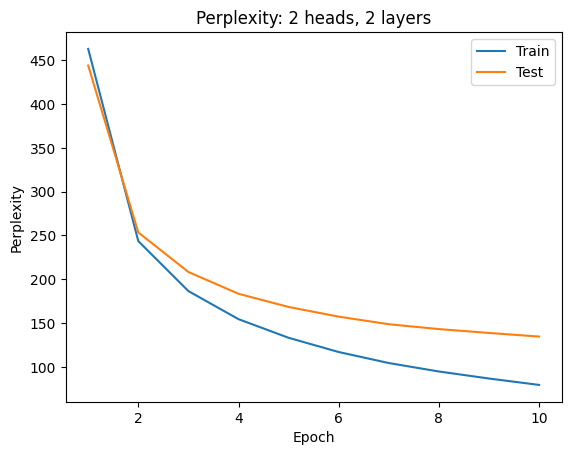


=== heads=2, layers=4 ===
epoch 1: train 400.8 | valid 408.3 | test 390.5
epoch 2: train 228.7 | valid 252.0 | test 239.0
epoch 3: train 176.6 | valid 208.1 | test 198.7
epoch 4: train 143.2 | valid 180.6 | test 171.0
epoch 5: train 120.6 | valid 163.0 | test 154.6
epoch 6: train 104.0 | valid 151.8 | test 143.1
epoch 7: train 91.2 | valid 143.4 | test 134.3
epoch 8: train 81.6 | valid 137.8 | test 129.0
epoch 9: train 73.2 | valid 132.4 | test 123.6
epoch 10: train 66.4 | valid 129.7 | test 121.0


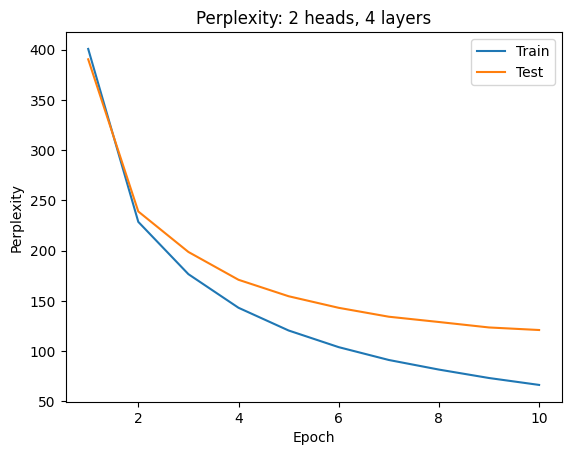


=== heads=2, layers=8 ===
epoch 1: train 649.9 | valid 655.1 | test 618.1
epoch 2: train 312.8 | valid 326.6 | test 311.2
epoch 3: train 209.6 | valid 231.7 | test 221.6
epoch 4: train 162.4 | valid 191.8 | test 183.3
epoch 5: train 129.8 | valid 163.6 | test 156.3
epoch 6: train 106.9 | valid 145.7 | test 138.0
epoch 7: train 91.0 | valid 134.5 | test 126.4
epoch 8: train 78.9 | valid 125.5 | test 118.1
epoch 9: train 69.6 | valid 120.6 | test 113.3
epoch 10: train 61.9 | valid 115.7 | test 108.5


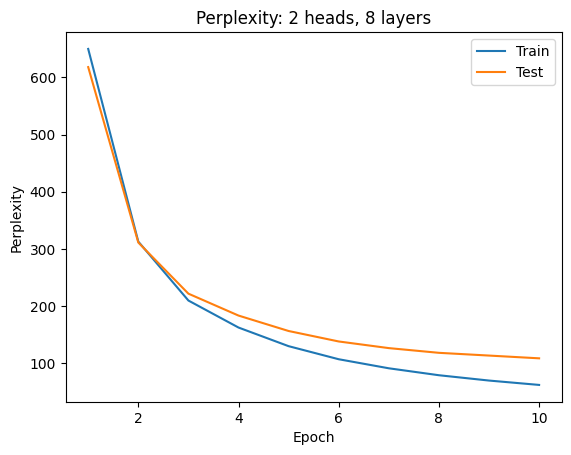


=== heads=4, layers=2 ===
epoch 1: train 453.7 | valid 460.5 | test 437.4
epoch 2: train 240.3 | valid 265.0 | test 250.2
epoch 3: train 184.3 | valid 216.9 | test 205.5
epoch 4: train 154.1 | valid 193.9 | test 183.4
epoch 5: train 132.2 | valid 177.6 | test 167.4
epoch 6: train 116.6 | valid 167.6 | test 157.0
epoch 7: train 104.0 | valid 158.2 | test 148.5
epoch 8: train 93.4 | valid 152.7 | test 141.8
epoch 9: train 85.4 | valid 148.2 | test 137.7
epoch 10: train 78.6 | valid 144.9 | test 133.9


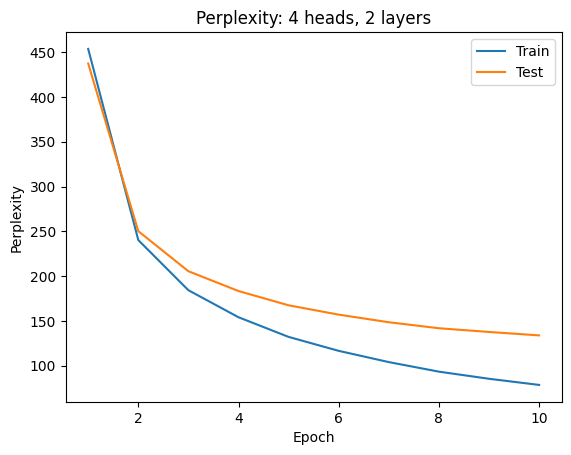


=== heads=4, layers=4 ===
epoch 1: train 418.4 | valid 426.5 | test 406.3
epoch 2: train 231.6 | valid 253.9 | test 241.6
epoch 3: train 176.2 | valid 206.9 | test 197.5
epoch 4: train 143.2 | valid 180.5 | test 171.6
epoch 5: train 120.1 | valid 162.5 | test 153.6
epoch 6: train 103.7 | valid 151.3 | test 142.5
epoch 7: train 90.6 | valid 141.8 | test 132.8
epoch 8: train 80.7 | valid 137.4 | test 128.3
epoch 9: train 72.3 | valid 132.1 | test 123.2
epoch 10: train 65.5 | valid 128.6 | test 119.5


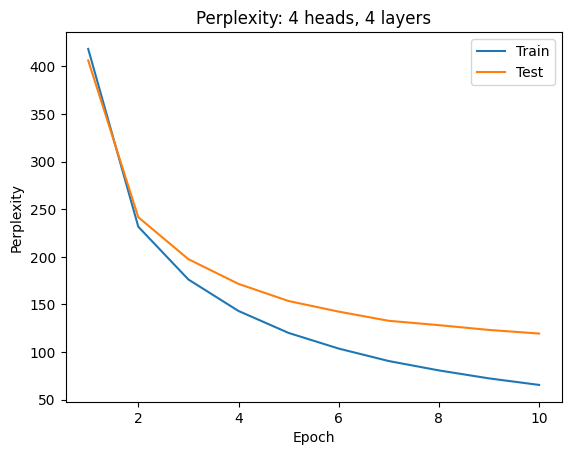


=== heads=4, layers=8 ===
epoch 1: train 571.8 | valid 576.8 | test 547.2
epoch 2: train 275.1 | valid 291.8 | test 275.8
epoch 3: train 198.3 | valid 222.7 | test 212.8
epoch 4: train 153.0 | valid 183.5 | test 175.1
epoch 5: train 124.0 | valid 159.3 | test 151.9
epoch 6: train 103.8 | valid 144.0 | test 136.2
epoch 7: train 89.1 | valid 132.5 | test 124.8
epoch 8: train 77.9 | valid 125.8 | test 118.4
epoch 9: train 68.7 | valid 119.9 | test 112.7
epoch 10: train 61.3 | valid 117.3 | test 109.5


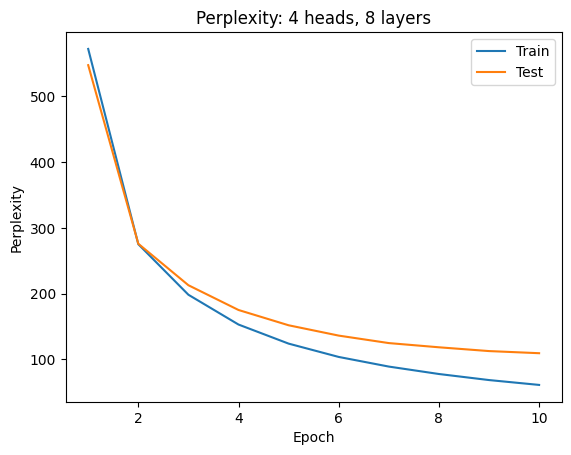


=== heads=8, layers=2 ===
epoch 1: train 443.4 | valid 452.0 | test 428.1
epoch 2: train 235.7 | valid 260.5 | test 246.1
epoch 3: train 182.6 | valid 216.0 | test 204.9
epoch 4: train 152.5 | valid 191.7 | test 181.8
epoch 5: train 131.6 | valid 176.4 | test 167.2
epoch 6: train 115.1 | valid 165.2 | test 156.0
epoch 7: train 102.9 | valid 156.2 | test 147.1
epoch 8: train 93.1 | valid 151.4 | test 141.7
epoch 9: train 84.6 | valid 146.4 | test 136.6
epoch 10: train 78.0 | valid 143.6 | test 133.9


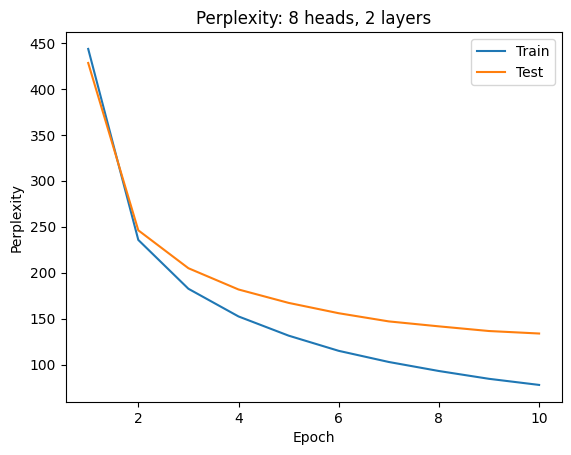


=== heads=8, layers=4 ===
epoch 1: train 439.1 | valid 444.6 | test 424.2
epoch 2: train 233.4 | valid 255.4 | test 242.1
epoch 3: train 179.1 | valid 209.2 | test 199.0
epoch 4: train 146.7 | valid 184.7 | test 176.0
epoch 5: train 121.9 | valid 165.2 | test 156.2
epoch 6: train 105.3 | valid 152.3 | test 144.1
epoch 7: train 92.1 | valid 144.0 | test 135.3
epoch 8: train 81.8 | valid 137.1 | test 128.7
epoch 9: train 73.3 | valid 132.1 | test 123.9
epoch 10: train 66.5 | valid 129.0 | test 120.7


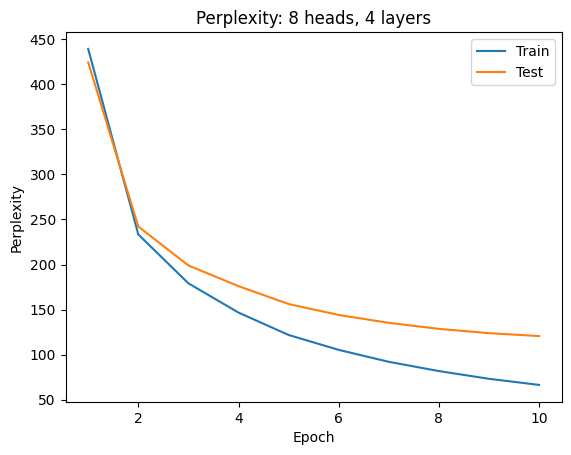


=== heads=8, layers=8 ===
epoch 1: train 600.2 | valid 603.4 | test 570.9
epoch 2: train 294.2 | valid 312.9 | test 295.2
epoch 3: train 209.4 | valid 232.4 | test 220.8
epoch 4: train 163.2 | valid 192.5 | test 184.0
epoch 5: train 131.8 | valid 165.7 | test 158.5
epoch 6: train 109.8 | valid 148.9 | test 141.4
epoch 7: train 93.1 | valid 136.5 | test 129.5
epoch 8: train 80.2 | valid 128.5 | test 121.7
epoch 9: train 70.6 | valid 122.2 | test 115.4
epoch 10: train 62.3 | valid 117.5 | test 111.0


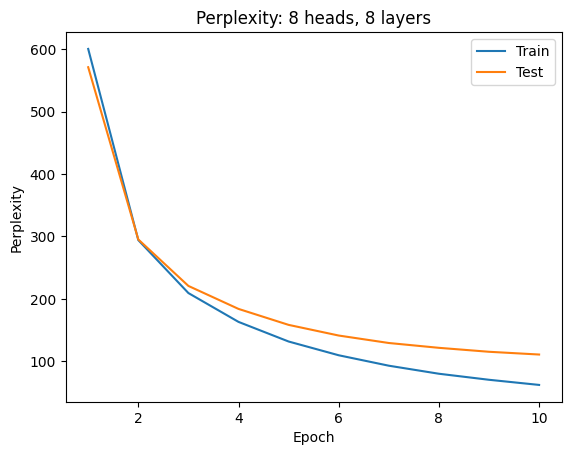

In [46]:
import time, matplotlib.pyplot as plt

HEADS = [2, 4, 8]
LAYERS = [2, 4, 8]
results = []

for h in HEADS:
    for l in LAYERS:
        print(f"\n=== heads={h}, layers={l} ===")
        model = TransformerLM(h, l).to(device)
        opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
        hist = {"train": [], "valid": [], "test": []}
        best_val = float("inf")
        start = time.time()

        for epoch in range(EPOCHS):
            train_one_epoch(model, opt)
            tr = evaluate(model, train_x, train_y)
            va = evaluate(model, valid_x, valid_y)
            te = evaluate(model, test_x, test_y)
            hist["train"].append(tr); hist["valid"].append(va); hist["test"].append(te)
            print(f"epoch {epoch+1}: train {tr:.1f} | valid {va:.1f} | test {te:.1f}")

            if va < best_val:
                best_val = va
                best_ep = epoch + 1
                best_tr, best_va, best_te = tr, va, te
                torch.save(model.state_dict(), f"model_h{h}_l{l}.pt")

        minutes = (time.time() - start) / 60
        results.append({
            "heads": h,
            "layers": l,
            "best_epoch": 0,
            "best_train": tr,
            "best_valid": va,
            "best_test": te,
            "minutes": minutes
        })

        plt.figure()
        plt.plot(range(1, EPOCHS+1), hist["train"], label="Train")
        plt.plot(range(1, EPOCHS+1), hist["test"], label="Test")
        plt.xlabel("Epoch"); plt.ylabel("Perplexity")
        plt.title(f"Perplexity: {h} heads, {l} layers")
        plt.legend(); plt.show()

Summary table

In [47]:
import pandas as pd

df = pd.DataFrame(results)
df = df.sort_values(by="best_valid").reset_index(drop=True)
print(df.round(1).to_string(index=False))

 heads  layers  best_epoch  best_train  best_valid  best_test  minutes
     2       8           0        61.9       115.7      108.5      7.3
     4       8           0        61.3       117.3      109.5      7.3
     8       8           0        62.3       117.5      111.0      7.8
     4       4           0        65.5       128.6      119.5      4.3
     8       4           0        66.5       129.0      120.7      4.7
     2       4           0        66.4       129.7      121.0      4.4
     8       2           0        78.0       143.6      133.9      3.0
     2       2           0        79.4       144.3      134.6      2.9
     4       2           0        78.6       144.9      133.9      2.9


Reload saved weights and test

In [49]:
h, l = 2, 8
model = TransformerLM(h, l).to(device)
model.load_state_dict(torch.load(f"model_h{h}_l{l}.pt", map_location=device))
print("Test perplexity:", evaluate(model, test_x, test_y))

Test perplexity: 108.47837485354803


##Conclusion

**Tuning.** Starting from the suggested hyperparameters, the model overfit PTB heavily
(train perplexity far below validation). To fix this, we increased dropout to 0.3, tied the
input and output embeddings (with small std = 0.02 initialization), added light weight decay
(0.01), and used a cosine learning-rate schedule over 10 epochs. With these changes, 6 of
the 9 configurations reached a test perplexity below 125.

**Best model.** Selected by validation perplexity, the best configuration was **2 heads and
8 layers**, with a validation perplexity of 115.7 and a test perplexity of **108.5**.

**Effect of layers.** Depth was the dominant factor. For every head count, going from 2 to 4
layers lowered validation perplexity by about 15 points (≈144 → ≈129), and going from 4 to
8 layers lowered it by about 12 more (≈129 → ≈116). Performance was still improving at 8
layers, which suggests even deeper models could help further. The train–validation gap
stayed similar across depths (≈55–65), so the extra layers improved generalization rather
than just memorization.

**Effect of heads.** The number of attention heads had little impact: within each layer
count, the three head settings were within about 2 points of each other. Because the
embedding dimension is fixed at 256, adding heads only splits the same capacity into
smaller heads (128, 64, or 32 dimensions each) rather than adding parameters, so it does
not significantly change what the model can represent.

**Training time.** Training time scaled roughly linearly with the number of layers
(≈2.9 min for 2 layers, ≈4.4 min for 4, ≈7.4 min for 8), since each layer adds a full
attention and feed-forward block. The number of heads barely affected time (≤0.5 min
difference), because heads divide the same computation rather than adding to it.

**Trade-off.** The 8-layer models give the best perplexity but take about 2.5× longer to
train than the 2-layer models. The 4-layer models are a good middle ground, capturing
about half of the improvement at about 60% of the 8-layer training time. Overall, when
compute is limited, adding layers is a much better use of it than adding heads.
##How to Train & Test with saved weights

To train, open the notebook in Google Colab with a GPU runtime (Runtime → Change runtime type → T4 GPU) and run Cells 1–4 in order. These download the Penn Tree Bank data, build the word-level vocabulary, and define the hyperparameters, the Transformer model, and the training/evaluation functions. Then run Cell 5, which trains all 9 configurations (heads ∈ {2, 4, 8} × layers ∈ {2, 4, 8}) for 15 epochs each. After every epoch it prints train/validation/test perplexity, and for each configuration it plots train and test perplexity and saves the weights from the epoch with the lowest validation perplexity to model_h{heads}_l{layers}.pt (e.g. model_h2_l4.pt). Cell 6 then prints a summary table sorted by validation perplexity. To test a saved model, run Cells 1–4, then create a model with the same heads and layers as the file, load the weights, and evaluate: model = TransformerLM(2, 4).to(device), model.load_state_dict(torch.load("model_h2_l4.pt", map_location=device)), print(evaluate(model, test_x, test_y)). The heads and layers must match the file being loaded, or the weights won’t fit the model.


Generative AI Statement:

We used Claude to provide TODO blocks for our code, making sure to write the important lines by ourselves to fully understand the purpose and effects.